# Modelagem Estatística — Rotatividade de Funcionários (HR Attrition)

**Dataset:** IBM HR Analytics Employee Attrition (1.470 funcionários, 35 variáveis).

**Problema de negócio:** a saída de funcionários (*attrition*) gera custo de reposição e perda de conhecimento. Queremos entender **quem sai**, **se a remuneração está associada à saída** e **quais ações são sustentadas por evidência estatística**.

**Estrutura:** (1) preparação dos dados → (2) análise exploratória → (3) testes de hipóteses e intervalos de confiança → (4) regressão linear → (5) integração regressão × hipóteses → (6) soluções, impacto e limitações.

**Por que este dataset:** é uma base com variável-alvo binária de interesse gerencial (saída), variáveis numéricas contínuas (renda, idade, tempo de casa) e categóricas (hora extra, estado civil, cargo), o que permite aplicar descritiva, testes e regressão linear no mesmo problema.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats 
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")
print(df.shape)
df.head()


(1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## 1. Limpeza e preparação dos dados

**Justificativas:**
- Verificamos valores ausentes, linhas duplicadas e colunas constantes. Colunas constantes têm variância zero e não explicam nada, por isso são removidas. `EmployeeNumber` é só identificador.
- O tratamento de ausentes está implementado de forma geral (mediana para numéricas, moda para categóricas): a mediana é robusta a assimetria e outliers (renda é assimétrica). Se a base não tiver ausentes, o tratamento não altera nada, e isso é verificado e documentado.
- Verificamos **inconsistências lógicas** (ex.: tempo no cargo maior que tempo na empresa) e **outliers** pelo critério do IQR. Outliers de renda são valores reais (cargos de diretoria), por isso são **mantidos**.

In [2]:
print("ausentes:", int(df.isna().sum().sum()), "| duplicadas:", int(df.duplicated().sum()))
constantes = [c for c in df.columns if df[c].nunique() == 1]
print("constantes removidas:", constantes)
df = df.drop(columns=constantes + ["EmployeeNumber"])

num = df.select_dtypes("number").columns
cat = df.columns.difference(num)
df[num] = df[num].fillna(df[num].median())
for c in cat:
    df[c] = df[c].fillna(df[c].mode().iloc[0])

inconsistencias = {
    "anos_empresa > anos_carreira": int((df.YearsAtCompany > df.TotalWorkingYears).sum()),
    "anos_cargo > anos_empresa": int((df.YearsInCurrentRole > df.YearsAtCompany).sum()),
    "anos_gerente > anos_empresa": int((df.YearsWithCurrManager > df.YearsAtCompany).sum()),
    "renda <= 0": int((df.MonthlyIncome <= 0).sum()),
}
print(inconsistencias)

q1, q3 = df.MonthlyIncome.quantile([0.25, 0.75])
iqr = q3 - q1
outliers = ((df.MonthlyIncome < q1 - 1.5 * iqr) | (df.MonthlyIncome > q3 + 1.5 * iqr)).sum()
print("outliers de renda (IQR):", int(outliers))
df.describe().T.round(2)

ausentes: 0 | duplicadas: 0
constantes removidas: ['EmployeeCount', 'Over18', 'StandardHours']
{'anos_empresa > anos_carreira': 0, 'anos_cargo > anos_empresa': 0, 'anos_gerente > anos_empresa': 0, 'renda <= 0': 0}
outliers de renda (IQR): 114


,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.92,9.14,18.0,30.0,36.0,43.00,60.0
DailyRate,1470.0,802.49,403.51,102.0,465.0,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.19,8.11,1.0,2.0,7.0,14.00,29.0
Education,1470.0,2.91,1.02,1.0,2.0,3.0,4.00,5.0
EnvironmentSatisfaction,1470.0,2.72,1.09,1.0,2.0,3.0,4.00,4.0
HourlyRate,1470.0,65.89,20.33,30.0,48.0,66.0,83.75,100.0
JobInvolvement,1470.0,2.73,0.71,1.0,2.0,3.0,3.00,4.0
JobLevel,1470.0,2.06,1.11,1.0,1.0,2.0,3.00,5.0
JobSatisfaction,1470.0,2.73,1.10,1.0,2.0,3.0,4.00,4.0
MonthlyIncome,1470.0,6502.93,4707.96,1009.0,2911.0,4919.0,8379.00,19999.0


## 2. Engenharia de variáveis

- `AttritionFlag` e `OverTimeFlag`: versões 0/1 para calcular médias (= proporções) e correlações.
- `AgeGroup` e `TenureBand`: faixas que facilitam comparações entre grupos e leitura gerencial.
- `PromotionStagnation`: anos desde a última promoção ÷ (anos na empresa + 1) — mede quanto do tempo de casa foi sem promoção, normalizando pelo tempo de casa. O `+1` evita divisão por zero.
- `LogIncome`: o logaritmo reduz a assimetria da renda e permite avaliar um modelo em escala multiplicativa.

In [3]:
df["AttritionFlag"] = (df.Attrition == "Yes").astype(int)
df["OverTimeFlag"] = (df.OverTime == "Yes").astype(int)
df["AgeGroup"] = pd.cut(df.Age, [17, 25, 35, 45, 55, 61], labels=["18-25", "26-35", "36-45", "46-55", "56+"])
df["TenureBand"] = pd.cut(df.YearsAtCompany, [-1, 1, 3, 5, 10, 40], labels=["0-1", "2-3", "4-5", "6-10", "11+"])
df["PromotionStagnation"] = df.YearsSinceLastPromotion / (df.YearsAtCompany + 1)
df["LogIncome"] = np.log(df.MonthlyIncome)
df[["AttritionFlag", "OverTimeFlag", "AgeGroup", "TenureBand", "PromotionStagnation", "LogIncome"]].head()

,AttritionFlag,OverTimeFlag,AgeGroup,TenureBand,PromotionStagnation,LogIncome
0,1,1,36-45,6-10,0.000000,8.698347
1,0,0,46-55,6-10,0.090909,8.542861
2,1,1,36-45,0-1,0.000000,7.644919
3,0,1,26-35,6-10,0.333333,7.975565
4,0,0,26-35,2-3,0.666667,8.151333


## 3. Análise exploratória

Começamos pela taxa geral de saída e pela comparação descritiva entre quem saiu e quem ficou. A taxa por categoria é comparada com a taxa geral (linha tracejada) para localizar grupos com comportamento diferente — esses grupos geram as **hipóteses** testadas na seção 4.

In [4]:
taxa = df.AttritionFlag.mean()
print(f"taxa geral de attrition: {taxa:.2%}  ({df.AttritionFlag.sum()} de {len(df)})")
df.groupby("Attrition")[["Age", "MonthlyIncome", "YearsAtCompany", "DistanceFromHome", "JobSatisfaction"]].agg(["mean", "median", "std"]).round(2).T

taxa geral de attrition: 16.12%  (237 de 1470)


Attrition                     No      Yes
Age              mean      37.56    33.61
                 median    36.00    32.00
                 std        8.89     9.69
MonthlyIncome    mean    6832.74  4787.09
                 median  5204.00  3202.00
                 std     4818.21  3640.21
YearsAtCompany   mean       7.37     5.13
                 median     6.00     3.00
                 std        6.10     5.95
DistanceFromHome mean       8.92    10.63
                 median     7.00     9.00
                 std        8.01     8.45
JobSatisfaction  mean       2.78     2.47
                 median     3.00     3.00
                 std        1.09     1.12

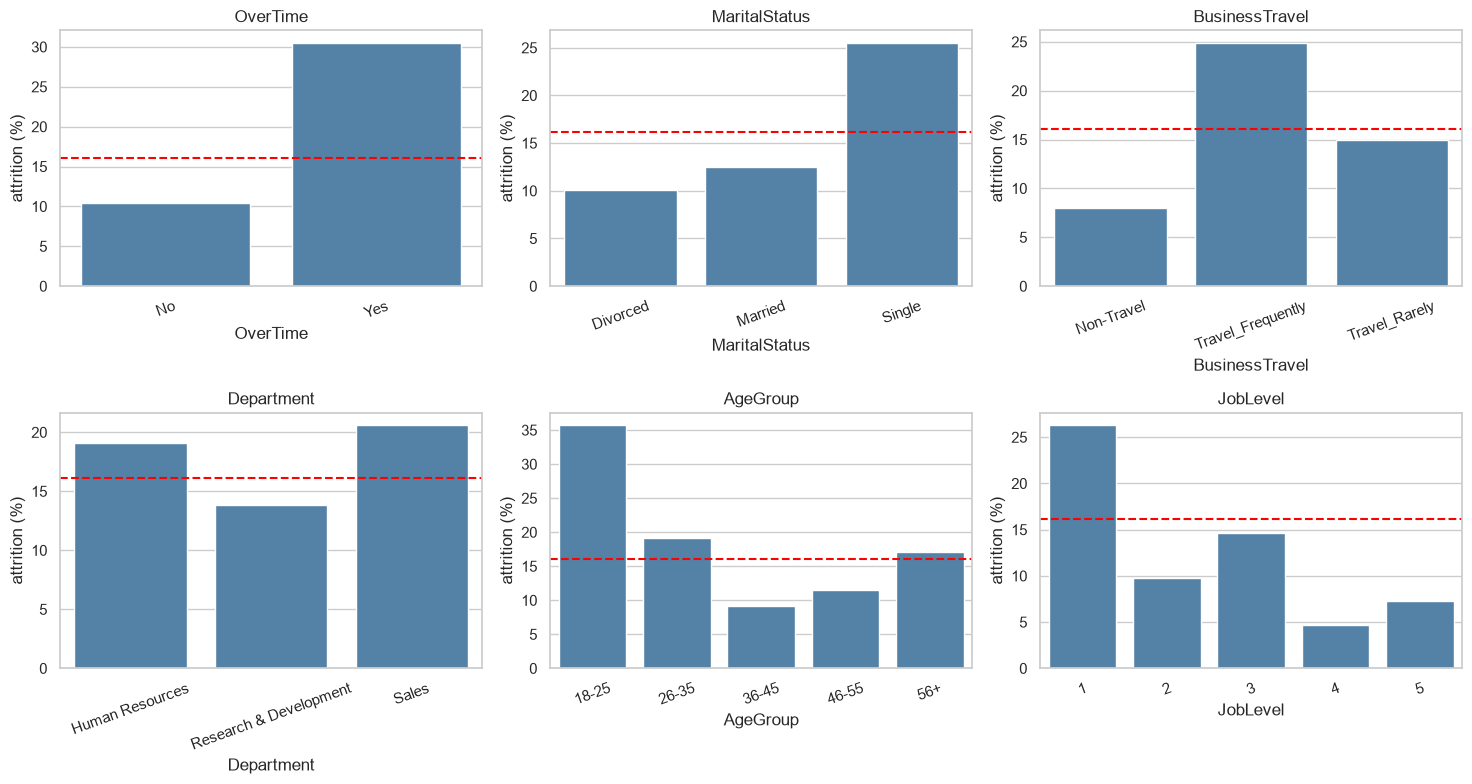

In [5]:
cats = ["OverTime", "MaritalStatus", "BusinessTravel", "Department", "AgeGroup", "JobLevel"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), cats):
    r = df.groupby(c, observed=True).AttritionFlag.mean().mul(100)
    sns.barplot(x=r.index.astype(str), y=r.values, ax=ax, color="steelblue")
    ax.axhline(taxa * 100, color="red", ls="--")
    ax.set_title(c)
    ax.set_ylabel("attrition (%)")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

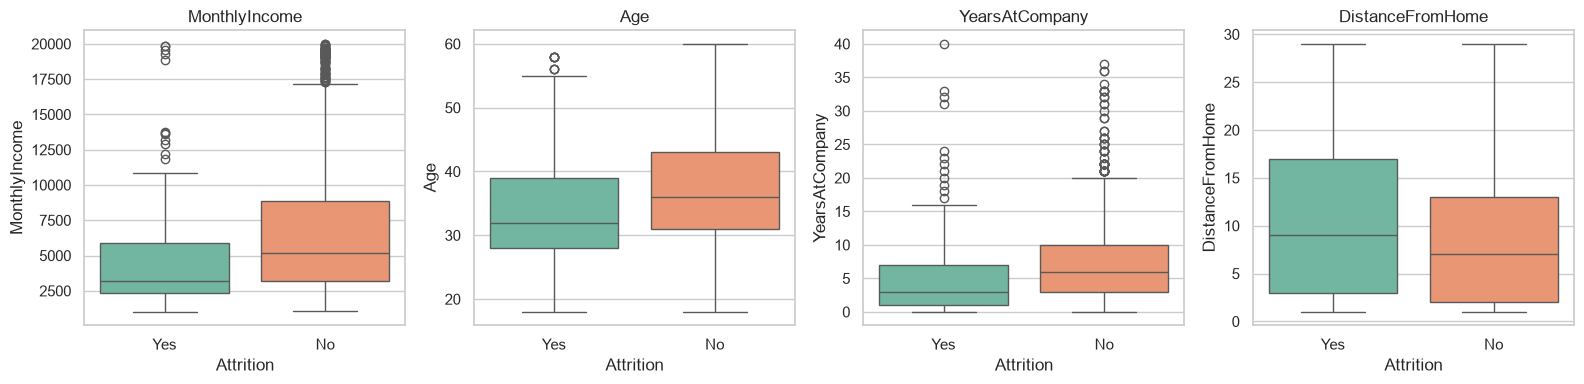

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, ["MonthlyIncome", "Age", "YearsAtCompany", "DistanceFromHome"]):
    sns.boxplot(data=df, x="Attrition", y=c, ax=ax, palette="Set2", hue="Attrition", legend=False)
    ax.set_title(c)
plt.tight_layout()
plt.show()

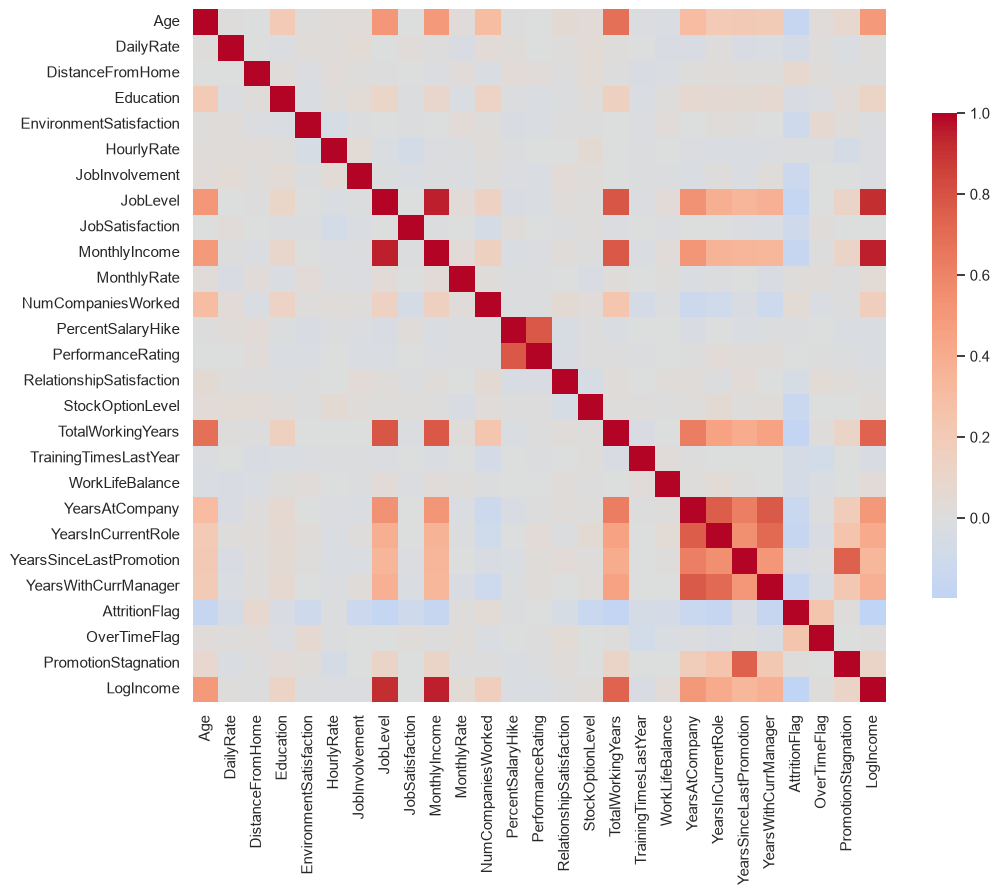

LogIncome                  -0.198
TotalWorkingYears          -0.171
JobLevel                   -0.169
YearsInCurrentRole         -0.161
MonthlyIncome              -0.160
Age                        -0.159
YearsWithCurrManager       -0.156
StockOptionLevel           -0.137
YearsAtCompany             -0.134
JobInvolvement             -0.130
JobSatisfaction            -0.103
EnvironmentSatisfaction    -0.103
WorkLifeBalance            -0.064
TrainingTimesLastYear      -0.059
DailyRate                  -0.057
RelationshipSatisfaction   -0.046
YearsSinceLastPromotion    -0.033
Education                  -0.031
PercentSalaryHike          -0.013
HourlyRate                 -0.007
PerformanceRating           0.003
PromotionStagnation         0.010
MonthlyRate                 0.015
NumCompaniesWorked          0.043
DistanceFromHome            0.078
OverTimeFlag                0.246
Name: AttritionFlag, dtype: float64

In [7]:
corr = df.select_dtypes("number").corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.7})
plt.show()
corr["AttritionFlag"].drop("AttritionFlag").sort_values().round(3)

## 4. Testes de hipóteses e intervalos de confiança

**Escolha dos testes:**
- Comparação de **proporções** entre dois grupos (ex.: saída com vs. sem hora extra): teste z para duas proporções e, de forma equivalente, qui-quadrado de independência. IC para a diferença de proporções pela aproximação normal (válida: todos os grupos têm $n\hat p$ e $n(1-\hat p)$ ≥ 5).
- Comparação de **médias** entre dois grupos independentes (renda, idade): teste t de **Welch**, que não assume variâncias iguais (os grupos têm tamanhos muito diferentes: ~16% saíram). Graus de liberdade pela aproximação de Welch–Satterthwaite. Como a renda é assimétrica, o resultado é confirmado com **Mann–Whitney** (não paramétrico). Com n grande, o Teorema Central do Limite sustenta a normalidade da média amostral.
- Associação entre duas **categóricas** com mais de duas classes (estado civil × saída): qui-quadrado de independência, com gl = (linhas−1)(colunas−1) e tamanho de efeito por V de Cramér.
- Nível de significância α = 0,05 e IC de 95% em todos os casos.

**Hipóteses (H0 × H1):** H1: $p_{HE}=p_{sem}$ × $p_{HE}\neq p_{sem}$. H2: $\mu_{renda,saiu}=\mu_{renda,ficou}$ × diferentes. H3: mesma estrutura para idade. H4: estado civil e saída independentes × dependentes.

In [8]:
def welch(a, b, conf=0.95):
    n1, n2 = len(a), len(b)
    v1, v2 = a.var(ddof=1), b.var(ddof=1)
    se = np.sqrt(v1 / n1 + v2 / n2)
    d = a.mean() - b.mean()
    gl = (v1 / n1 + v2 / n2) ** 2 / ((v1 / n1) ** 2 / (n1 - 1) + (v2 / n2) ** 2 / (n2 - 1))
    t = d / se
    p = 2 * stats.t.sf(abs(t), gl)
    tc = stats.t.ppf(1 - (1 - conf) / 2, gl)
    return {"dif_medias": d, "t": t, "gl": gl, "p_valor": p, "ic_inf": d - tc * se, "ic_sup": d + tc * se}

def ic_diff_prop(x1, n1, x2, n2, conf=0.95):
    p1, p2 = x1 / n1, x2 / n2
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    z = stats.norm.ppf(1 - (1 - conf) / 2)
    return p1 - p2 - z * se, p1 - p2 + z * se

k, n = df.AttritionFlag.sum(), len(df)
ic_geral = stats.binomtest(int(k), n).proportion_ci(confidence_level=0.95, method="wilson")
print(f"taxa geral = {k / n:.4f} | IC95% (Wilson) = [{ic_geral.low:.4f}, {ic_geral.high:.4f}]")

taxa geral = 0.1612 | IC95% (Wilson) = [0.1433, 0.1809]


In [9]:
com = df[df.OverTime == "Yes"].AttritionFlag
sem = df[df.OverTime == "No"].AttritionFlag
x1, n1, x2, n2 = com.sum(), len(com), sem.sum(), len(sem)
pp = (x1 + x2) / (n1 + n2)
z = (x1 / n1 - x2 / n2) / np.sqrt(pp * (1 - pp) * (1 / n1 + 1 / n2))
p_z = 2 * stats.norm.sf(abs(z))
lo, hi = ic_diff_prop(x1, n1, x2, n2)
tab_ot = pd.crosstab(df.OverTime, df.Attrition)
chi2_ot, p_chi_ot, gl_ot, _ = stats.chi2_contingency(tab_ot, correction=False)
print(f"H1 hora extra: p_com={x1/n1:.4f} p_sem={x2/n2:.4f} dif={x1/n1-x2/n2:.4f}")
print(f"z={z:.3f} p={p_z:.3e} | chi2={chi2_ot:.3f} gl={gl_ot} p={p_chi_ot:.3e} | z^2={z**2:.3f}")
print(f"IC95% da diferença de proporções: [{lo:.4f}, {hi:.4f}]")

H1 hora extra: p_com=0.3053 p_sem=0.1044 dif=0.2009
z=9.436 p=3.862e-21 | chi2=89.044 gl=1 p=3.862e-21 | z^2=89.044
IC95% da diferença de proporções: [0.1530, 0.2489]


In [10]:
saiu = df[df.Attrition == "Yes"]
ficou = df[df.Attrition == "No"]
resultados = {}
for var in ["MonthlyIncome", "Age"]:
    r = welch(saiu[var], ficou[var])
    r["mannwhitney_p"] = stats.mannwhitneyu(saiu[var], ficou[var]).pvalue
    resultados[var] = r
pd.DataFrame(resultados).T.round(6)

,dif_medias,t,gl,p_valor,ic_inf,ic_sup,mannwhitney_p
MonthlyIncome,-2045.646832,-7.482622,412.740748,0.0,-2583.050149,-1508.243516,0.0
Age,-3.953638,-5.828012,316.931112,0.0,-5.288346,-2.618930,0.0


In [11]:
tab_ms = pd.crosstab(df.MaritalStatus, df.Attrition)
chi2_ms, p_ms, gl_ms, esperado = stats.chi2_contingency(tab_ms, correction=False)
v_cramer = np.sqrt(chi2_ms / (tab_ms.values.sum() * (min(tab_ms.shape) - 1)))
print(f"H4 estado civil: chi2={chi2_ms:.3f} gl={gl_ms} p={p_ms:.3e} V de Cramér={v_cramer:.3f}")
print("menor frequência esperada:", esperado.min().round(1))
tab_ms

H4 estado civil: chi2=46.164 gl=2 p=9.456e-11 V de Cramér=0.177
menor frequência esperada: 52.7


Attrition,No,Yes
MaritalStatus,,
Divorced,294,33
Married,589,84
Single,350,120


## 5. Regressão linear múltipla (variável dependente: `MonthlyIncome`)

**Por que renda como variável dependente?** A regressão linear exige alvo contínuo, e a saída (0/1) é binária. A renda é contínua e ligada ao problema: modelar o salário "esperado" para o perfil de cada funcionário permite medir se quem sai está **abaixo do esperado** (seção 6).

**Preditores:** `Age`, `JobLevel`, `TotalWorkingYears`, `YearsAtCompany`, `YearsSinceLastPromotion` — variáveis de perfil e carreira com relação plausível com salário.

**Método:** separação treino/teste (80/20, `random_state=42`) para avaliar em dados não vistos. A inferência (erro-padrão, t, p, IC) usa MQO implementado diretamente: $\hat\beta=(X'X)^{-1}X'y$, $s^2=SQR/(n-k)$, $Var(\hat\beta)=s^2(X'X)^{-1}$, com **gl residual = n − k** (k = nº de parâmetros incluindo o intercepto). Teste F global: H0: todos os coeficientes (exceto o intercepto) são zero.

In [12]:
feats = ["Age", "JobLevel", "TotalWorkingYears", "YearsAtCompany", "YearsSinceLastPromotion"]
X_tr, X_te, y_tr, y_te = train_test_split(df[feats], df.MonthlyIncome, test_size=0.2, random_state=42)

def ols(X, y, conf=0.95):
    A = np.column_stack([np.ones(len(X)), X.values])
    n, k = A.shape
    inv = np.linalg.inv(A.T @ A)
    beta = inv @ A.T @ y.values
    res = y.values - A @ beta
    gl = n - k
    s2 = res @ res / gl
    se = np.sqrt(np.diag(inv) * s2)
    t = beta / se
    p = 2 * stats.t.sf(abs(t), gl)
    tc = stats.t.ppf(1 - (1 - conf) / 2, gl)
    tabela = pd.DataFrame({"coef": beta, "erro_padrao": se, "t": t, "p_valor": p,
                           "ic_inf": beta - tc * se, "ic_sup": beta + tc * se},
                          index=["const"] + list(X.columns))
    sst = ((y.values - y.mean()) ** 2).sum()
    r2 = 1 - res @ res / sst
    r2aj = 1 - (1 - r2) * (n - 1) / gl
    F = (r2 / (k - 1)) / ((1 - r2) / gl)
    resumo = {"n": n, "gl_residual": gl, "R2": r2, "R2_ajustado": r2aj, "F": F, "p_F": stats.f.sf(F, k - 1, gl)}
    return tabela, resumo, res, s2

tabela, resumo, res_tr, s2 = ols(X_tr, y_tr)
print(tabela.round(4))
print({k: round(float(v), 4) for k, v in resumo.items()})

                              coef  erro_padrao        t  p_valor     ic_inf     ic_sup
const                   -1539.8060     201.6302  -7.6368   0.0000 -1935.4033 -1144.2088
Age                       -10.3406       6.3829  -1.6201   0.1055   -22.8638     2.1826
JobLevel                 3820.5947      60.8882  62.7477   0.0000  3701.1324  3940.0570
TotalWorkingYears          59.9593      11.2891   5.3112   0.0000    37.8101    82.1085
YearsAtCompany            -21.6399      10.3421  -2.0924   0.0366   -41.9310    -1.3487
YearsSinceLastPromotion    17.7793      16.7455   1.0617   0.2886   -15.0753    50.6339
{'n': 1176.0, 'gl_residual': 1170.0, 'R2': 0.9081, 'R2_ajustado': 0.9077, 'F': 2312.8424, 'p_F': 0.0}


In [13]:
modelo = LinearRegression().fit(X_tr, y_tr)
pred_te = modelo.predict(X_te)
print("coeficientes sklearn:", dict(zip(feats, modelo.coef_.round(4))), "| intercepto:", round(modelo.intercept_, 4))
print(f"TESTE  R2={r2_score(y_te, pred_te):.4f} RMSE={np.sqrt(mean_squared_error(y_te, pred_te)):.2f} MAE={mean_absolute_error(y_te, pred_te):.2f}")
print(f"TREINO R2={modelo.score(X_tr, y_tr):.4f}")
cv = cross_val_score(LinearRegression(), df[feats], df.MonthlyIncome, cv=5, scoring="r2")
print("R2 validação cruzada (5 folds):", cv.round(4), "| média:", cv.mean().round(4))

coeficientes sklearn: {'Age': np.float64(-10.3406), 'JobLevel': np.float64(3820.5947), 'TotalWorkingYears': np.float64(59.9593), 'YearsAtCompany': np.float64(-21.6399), 'YearsSinceLastPromotion': np.float64(17.7793)} | intercepto: -1539.806
TESTE  R2=0.8944 RMSE=1519.42 MAE=1175.88
TREINO R2=0.9081
R2 validação cruzada (5 folds): [0.9035 0.9046 0.9137 0.9131 0.8829] | média: 0.9036


### Pressupostos do modelo
- **Multicolinearidade:** VIF por preditor (VIF = 1/(1−R²) de regredir o preditor nos demais). Valores acima de ~5–10 indicam coeficientes instáveis.
- **Linearidade e homocedasticidade:** gráfico de resíduos × ajustados e teste de **Breusch–Pagan** (H0: variância constante; estatística LM = n·R² da regressão do resíduo² nos preditores, χ² com gl = nº de preditores).
- **Normalidade dos resíduos:** gráfico Q–Q e teste de Shapiro–Wilk (com n grande qualquer desvio pequeno é "significativo", então o Q–Q pesa mais).

VIF:
 Age                        1.98
JobLevel                   2.59
TotalWorkingYears          4.47
YearsAtCompany             2.28
YearsSinceLastPromotion    1.57
dtype: float64
Breusch-Pagan: LM=72.29 gl=5 p=3.421e-14
Shapiro-Wilk dos resíduos: ShapiroResult(statistic=np.float64(0.9896679786056682), pvalue=np.float64(2.3248179606176382e-07))


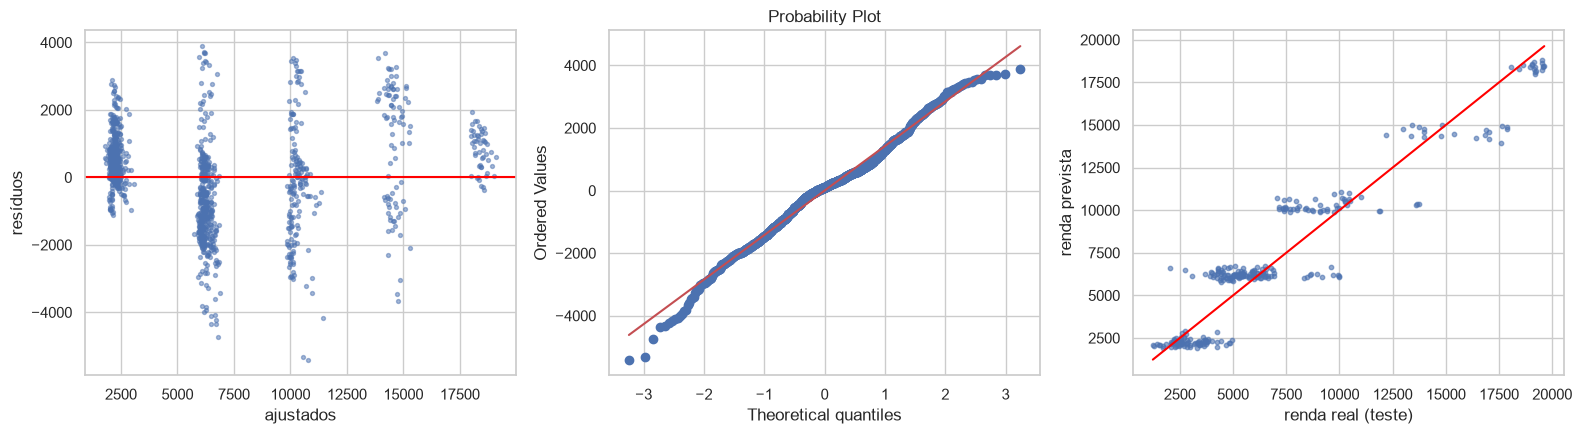

In [14]:
vif = pd.Series({c: 1 / (1 - LinearRegression().fit(X_tr.drop(columns=c), X_tr[c]).score(X_tr.drop(columns=c), X_tr[c])) for c in feats})
print("VIF:\n", vif.round(2))

r2_bp = LinearRegression().fit(X_tr, res_tr ** 2).score(X_tr, res_tr ** 2)
lm = len(X_tr) * r2_bp
print(f"Breusch-Pagan: LM={lm:.2f} gl={len(feats)} p={stats.chi2.sf(lm, len(feats)):.3e}")
print("Shapiro-Wilk dos resíduos:", stats.shapiro(res_tr))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ajust = modelo.predict(X_tr)
axes[0].scatter(ajust, res_tr, s=8, alpha=0.5)
axes[0].axhline(0, color="red")
axes[0].set_xlabel("ajustados")
axes[0].set_ylabel("resíduos")
stats.probplot(res_tr, plot=axes[1])
axes[2].scatter(y_te, pred_te, s=10, alpha=0.6)
axes[2].plot([y_te.min(), y_te.max()], [y_te.min(), y_te.max()], color="red")
axes[2].set_xlabel("renda real (teste)")
axes[2].set_ylabel("renda prevista")
plt.tight_layout()
plt.show()

### Alternativa em escala logarítmica
Se houver heterocedasticidade/assimetria, o modelo com `LogIncome` costuma estabilizar a variância. Os coeficientes passam a ser lidos como variação **percentual** aproximada ($100\cdot\beta$ %) na renda.

In [15]:
Xl_tr, Xl_te, yl_tr, yl_te = train_test_split(df[feats], df.LogIncome, test_size=0.2, random_state=42)
tab_log, resumo_log, res_log, _ = ols(Xl_tr, yl_tr)
m_log = LinearRegression().fit(Xl_tr, yl_tr)
print(tab_log.round(4))
print({k: round(float(v), 4) for k, v in resumo_log.items()})
print("R2 teste (log):", round(r2_score(yl_te, m_log.predict(Xl_te)), 4))
r2_bp_log = LinearRegression().fit(Xl_tr, res_log ** 2).score(Xl_tr, res_log ** 2)
print("Breusch-Pagan (log) p =", stats.chi2.sf(len(Xl_tr) * r2_bp_log, len(feats)))

                           coef  erro_padrao         t  p_valor  ic_inf  ic_sup
const                    7.3329       0.0366  200.5642   0.0000  7.2611  7.4046
Age                      0.0020       0.0012    1.7265   0.0845 -0.0003  0.0043
JobLevel                 0.5336       0.0110   48.3325   0.0000  0.5120  0.5553
TotalWorkingYears        0.0022       0.0020    1.0670   0.2862 -0.0018  0.0062
YearsAtCompany           0.0014       0.0019    0.7628   0.4458 -0.0022  0.0051
YearsSinceLastPromotion  0.0022       0.0030    0.7202   0.4716 -0.0038  0.0081
{'n': 1176.0, 'gl_residual': 1170.0, 'R2': 0.8513, 'R2_ajustado': 0.8507, 'F': 1339.5977, 'p_F': 0.0}
R2 teste (log): 0.8254
Breusch-Pagan (log) p = 0.019555931576905283


### Previsão de novos valores
Usamos o modelo em escala original para prever a renda de perfis novos. O intervalo de **predição** usa $\hat y \pm t_{\alpha/2,\,gl}\sqrt{s^2(1+x_0'(X'X)^{-1}x_0)}$: é mais largo que o IC da média porque inclui a variabilidade individual.

In [16]:
novos = pd.DataFrame({
    "Age": [24, 33, 41, 52],
    "JobLevel": [1, 2, 3, 5],
    "TotalWorkingYears": [2, 10, 18, 30],
    "YearsAtCompany": [1, 5, 10, 20],
    "YearsSinceLastPromotion": [0, 2, 3, 5],
})
A_tr = np.column_stack([np.ones(len(X_tr)), X_tr.values])
inv_tr = np.linalg.inv(A_tr.T @ A_tr)
A_novos = np.column_stack([np.ones(len(novos)), novos.values])
previsto = modelo.predict(novos)
margem = stats.t.ppf(0.975, resumo["gl_residual"]) * np.sqrt(s2 * (1 + np.einsum("ij,jk,ik->i", A_novos, inv_tr, A_novos)))
out = novos.copy()
out["renda_prevista"] = previsto.round(0)
out["pred_inf_95"] = (previsto - margem).round(0)
out["pred_sup_95"] = (previsto + margem).round(0)
out

,Age,JobLevel,TotalWorkingYears,YearsAtCompany,YearsSinceLastPromotion,renda_prevista,pred_inf_95,pred_sup_95
0,24,1,2,1,0,2131.0,-679.0,4941.0
1,33,2,10,5,2,6287.0,3479.0,9095.0
2,41,3,18,10,3,10414.0,7606.0,13223.0
3,52,5,30,20,5,18480.0,15663.0,21298.0


## 6. Integração: a regressão alimenta os testes de hipótese

Para saber se quem sai está **mal pago para o próprio perfil**, e não apenas ganhando menos porque é mais jovem ou júnior, criamos `IncomeGap = renda real − renda prevista pelo modelo`. Valores negativos indicam renda abaixo do esperado para aquele perfil. Testamos (Welch) se a média do `IncomeGap` difere entre quem saiu e quem ficou, e se o gap difere entre os grupos de hora extra.

In [17]:
modelo_final = LinearRegression().fit(df[feats], df.MonthlyIncome)
df["IncomeGap"] = df.MonthlyIncome - modelo_final.predict(df[feats])
r_gap = welch(df[df.Attrition == "Yes"].IncomeGap, df[df.Attrition == "No"].IncomeGap)
print("H5 IncomeGap saiu vs ficou:", {k: round(float(v), 5) for k, v in r_gap.items()})
r_gap_ot = welch(df[df.OverTime == "Yes"].IncomeGap, df[df.OverTime == "No"].IncomeGap)
print("IncomeGap hora extra vs sem:", {k: round(float(v), 5) for k, v in r_gap_ot.items()})
df.groupby("Attrition").IncomeGap.describe().round(1)

H5 IncomeGap saiu vs ficou: {'dif_medias': 26.34273, 't': 0.29264, 'gl': 382.74024, 'p_valor': 0.76995, 'ic_inf': -150.64507, 'ic_sup': 203.33053}
IncomeGap hora extra vs sem: {'dif_medias': 48.72712, 't': 0.58933, 'gl': 780.81797, 'p_valor': 0.55581, 'ic_inf': -113.57877, 'ic_sup': 211.03301}


,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,1233.0,-4.2,1485.0,-5294.9,-1008.9,92.7,822.1,3909.9
Yes,237.0,22.1,1223.3,-5366.4,-552.0,101.4,605.9,3765.4


## 7. Impacto das soluções propostas
Estimamos o efeito de uma ação sobre hora extra: se a taxa de saída de quem faz hora extra caísse até a taxa de quem não faz, quantas saídas seriam evitadas? Os limites vêm do IC95% da diferença de proporções (seção 4), propagando a incerteza do estudo.

In [18]:
n_ot = int((df.OverTime == "Yes").sum())
dif = x1 / n1 - x2 / n2
print(f"funcionários em hora extra: {n_ot}")
print(f"saídas evitáveis (estimativa pontual): {n_ot * dif:.1f}  = {n_ot * dif / df.AttritionFlag.sum():.1%} das saídas")
print(f"intervalo (IC95% da diferença): [{n_ot * lo:.1f}, {n_ot * hi:.1f}]")
df.groupby(["OverTime", "MaritalStatus"]).AttritionFlag.agg(["mean", "size"]).round(3)

funcionários em hora extra: 416
saídas evitáveis (estimativa pontual): 83.6  = 35.3% das saídas
intervalo (IC95% da diferença): [63.6, 103.5]


mean  size
OverTime MaritalStatus             
No       Divorced       0.061   228
         Married        0.084   487
         Single         0.162   339
Yes      Divorced       0.192    99
         Married        0.231   186
         Single         0.496   131

## 8. Conclusões e soluções práticas

**Principais resultados (α = 0,05, IC 95%)**
- A taxa geral de saída é de **16,1%** (IC de Wilson: 14,3% a 18,1%).
- **Hora extra (H1):** 30,5% de saída com hora extra contra 10,4% sem. Diferença de 20,1 p.p. (IC 95%: 15,3 a 24,9 p.p.; z = 9,44; p < 0,001). Rejeita-se H0.
- **Renda (H2):** quem saiu ganha em média R$ 2.046 a menos (IC 95%: −2.583 a −1.508; t de Welch = −7,48; gl ≈ 413; p < 0,001), confirmado por Mann–Whitney. **Idade (H3):** diferença de −3,95 anos (IC 95%: −5,29 a −2,62).
- **Estado civil (H4):** χ² = 46,2 (gl = 2; p < 0,001); solteiros saem mais (25,5%) que divorciados (9,2%). V de Cramér = 0,18: efeito pequeno a moderado.
- **Regressão:** R² = 0,908 (treino), 0,894 (teste), 0,904 (validação cruzada), RMSE ≈ R$ 1.519. O nível do cargo domina: cada nível adicional soma cerca de R$ 3.821 (IC 95%: 3.701 a 3.940), mantidas as demais variáveis. Idade e anos desde a última promoção têm IC que inclui zero.
- **Pressupostos:** VIF máximo 4,47 (sem multicolinearidade severa), mas Breusch–Pagan rejeita variância constante e os resíduos se afastam da normalidade. O modelo em log reduz o problema, porém explica menos (R² teste 0,825 em escala log). Mantemos o modelo em escala original pela interpretação em reais e tratamos a heterocedasticidade como limitação (erros-padrão robustos seriam a melhoria natural).
- **Integração (H5):** o `IncomeGap` de quem saiu não difere do de quem ficou (diferença ≈ R$ 26; IC 95%: −151 a 203; p = 0,77). A renda menor de quem sai é explicada pelo **perfil** (nível e carreira), não por pagamento abaixo do esperado para o perfil.

**Recomendações (cada uma ligada a um teste):**
1. **Revisar a carga de hora extra** — maior diferença de saída observada (H1). Se a taxa de quem faz hora extra caísse para a de quem não faz, seriam evitadas cerca de **84 saídas (≈ 35% do total)**, entre 64 e 104 pelo IC.
2. **Acompanhamento de integração e carreira para perfis júnior, jovens e solteiros** (H2, H3, H4), onde a saída se concentra; a combinação solteiro + hora extra chega a 49,6% de saída.
3. **Não adotar reajuste salarial linear como solução principal:** o H5 não encontrou evidência de que quem sai seja pago abaixo do esperado para o perfil. Priorizar progressão de nível, que é o que o modelo mostra mover a renda.

**Limitações:** dados observacionais e de um único momento (associação não implica causa; hora extra pode ser efeito e não causa de insatisfação); base sintética da IBM, com generalização limitada; múltiplos testes (com Bonferroni, α = 0,01, as conclusões H1–H4 se mantêm); a regressão linear modela renda e não a saída (um modelo logístico seria o complemento natural); heterocedasticidade e intervalos de predição que podem incluir valores negativos para perfis juniores; a estimativa de impacto assume que a diferença observada seria causal.